# Are You Actually Replaceable? What the Data Says About AI and Your Career
### Phase 1 — Data Familiarization & Wrangling
**Group P33** — Mika Ohayon, Akshaya Somasundaram, Harini Champooranan

This notebook works through the first phase of the project: understanding the two raw
datasets described in the proposal (BLS OEWS employment/wage data and the Felten–Raj–Seamans
AIOE occupational exposure scores) and cleaning them so they are ready for the regression
analysis planned in later phases. Cleaned versions of both datasets are saved out at the end
(`dataset1_new.csv`, `dataset2_new.csv`) so later phases can load them directly instead of
re-running this cleaning logic.

## Step 0 — Project Goal

Public debate about AI and jobs has mostly run on speculation, not evidence. The goal of this
project is to replace that speculation with data: we want to find out whether U.S. occupations
that were already flagged as highly "exposed" to AI — using the pre-existing AIOE
(AI Occupational Exposure) score from Felten, Raj, and Seamans — are actually showing the wage
and employment shifts that AI-displacement narratives predict, using real BLS Occupational
Employment and Wage Statistics (OEWS) records. Concretely, we will link each occupation's AIOE
score to its national employment and wage figures by SOC code, then run a linear regression
(with an interaction term for skill/education level) to test whether AIOE predicts real outcomes,
and whether that relationship differs for high-skill versus low-skill, high-exposure occupations.
Before any of that modeling can happen, this notebook's job is to get both source datasets fully
understood and cleaned, since a regression built on unexamined or badly formatted data would not
be trustworthy evidence one way or another.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 40)
DATA_DIR = 'data'


## Step 1 — Data Familiarization

The proposal names two datasets:

1. **Dataset 1 — BLS OEWS** (`national_M2025_dl.xlsx`): the federal survey product giving real
   national employment counts and wages by occupation.
2. **Dataset 2 — AIOE Scores** (`AIOE_DataAppendix.xlsx`, Appendix A): the official replication
   data for Felten, Raj & Seamans, giving each occupation's AI exposure score.

The AIOE workbook ships five appendices total, but our research question only needs
**Appendix A**, since we join to OEWS on SOC occupation code, not on industry (NAICS) or
geography (FIPS). Appendices B–E are not used in this project.

### Step 1a — Load Dataset 1 (BLS OEWS) and get its shape

In [2]:
oews_raw = pd.read_excel(f'{DATA_DIR}/national_M2025_dl.xlsx', sheet_name='national_M2025_dl')
print('Shape (rows, columns):', oews_raw.shape)
oews_raw.head()

Shape (rows, columns): (1401, 32)


,AREA,AREA_TITLE,AREA_TYPE,PRIM_STATE,NAICS,NAICS_TITLE,I_GROUP,OWN_CODE,OCC_CODE,OCC_TITLE,O_GROUP,TOT_EMP,EMP_PRSE,JOBS_1000,LOC_QUOTIENT,PCT_TOTAL,PCT_RPT,H_MEAN,A_MEAN,MEAN_PRSE,H_PCT10,H_PCT25,H_MEDIAN,H_PCT75,H_PCT90,A_PCT10,A_PCT25,A_MEDIAN,A_PCT75,A_PCT90,ANNUAL,HOURLY
0,99,U.S.,1,US,0,Cross-industry,cross-industry,1235,00-0000,All Occupations,total,155495730,0.0,NaN,NaN,NaN,NaN,33.54,69770,0.1,15,18.07,24.51,38.71,61.81,31200,37590,50980,80520,128560,NaN,NaN
1,99,U.S.,1,US,0,Cross-industry,cross-industry,1235,11-0000,Management Occupations,major,11132700,0.2,NaN,NaN,NaN,NaN,69.84,145260,0.2,28.91,39.89,60.83,84.75,123.71,60130,82970,126520,176280,257310,NaN,NaN
2,99,U.S.,1,US,0,Cross-industry,cross-industry,1235,11-1000,Top Executives,minor,3720520,0.3,NaN,NaN,NaN,NaN,68.33,142120,0.3,24.27,35.22,52.17,82.85,134.48,50480,73260,108510,172330,279710,NaN,NaN
3,99,U.S.,1,US,0,Cross-industry,cross-industry,1235,11-1010,Chief Executives,broad,204350,3.1,NaN,NaN,NaN,NaN,129.63,269630,1.9,36.39,62.28,102.88,171.25,244.1,75700,129540,213990,356200,507730,NaN,NaN
4,99,U.S.,1,US,0,Cross-industry,cross-industry,1235,11-1011,Chief Executives,detailed,204350,3.1,NaN,NaN,NaN,NaN,129.63,269630,1.9,36.39,62.28,102.88,171.25,244.1,75700,129540,213990,356200,507730,NaN,NaN


**Summary:** Dataset 1 has **1,401 rows and 32 columns**. Every row has
`AREA_TITLE = 'U.S.'` and `NAICS_TITLE = 'Cross-industry'` — this file is the *national,
all-industries* cut of OEWS, which is exactly the scope our research question needs.

### Step 1b — Classify & summarize Dataset 1's columns

We classify each column, then summarize: a bar chart + mode for the categorical columns that
actually vary, and `describe()` + histograms for the quantitative columns.

In [3]:
oews_raw.dtypes

AREA              int64
AREA_TITLE          str
AREA_TYPE         int64
PRIM_STATE          str
NAICS             int64
NAICS_TITLE         str
I_GROUP             str
OWN_CODE          int64
OCC_CODE            str
OCC_TITLE           str
O_GROUP             str
TOT_EMP           int64
EMP_PRSE        float64
JOBS_1000       float64
LOC_QUOTIENT    float64
PCT_TOTAL       float64
PCT_RPT         float64
H_MEAN           object
A_MEAN           object
MEAN_PRSE       float64
H_PCT10          object
H_PCT25          object
H_MEDIAN         object
H_PCT75          object
H_PCT90          object
A_PCT10          object
A_PCT25          object
A_MEDIAN         object
A_PCT75          object
A_PCT90          object
ANNUAL           object
HOURLY           object
dtype: object

| Column(s) | Type | Notes |
|---|---|---|
| `AREA`, `AREA_TITLE`, `AREA_TYPE`, `PRIM_STATE`, `NAICS`, `NAICS_TITLE`, `I_GROUP`, `OWN_CODE` | Categorical (nominal) | Constant in this file — it's the single national/cross-industry cut |
| `OCC_CODE`, `OCC_TITLE` | Categorical (nominal) | 6-digit SOC identifier + name, ~1 per row |
| `O_GROUP` | Categorical (**ordinal**) | SOC hierarchy level: total → major → minor → broad → detailed |
| `ANNUAL`, `HOURLY` | Categorical (nominal, binary flag) | `TRUE`/blank flag for annual-only or hourly-only pay |
| `TOT_EMP` | Quantitative (**discrete**) | Headcount, rounded to nearest 10 |
| `EMP_PRSE`, `MEAN_PRSE` | Quantitative (continuous) | Percent relative standard error |
| `JOBS_1000`, `LOC_QUOTIENT`, `PCT_TOTAL`, `PCT_RPT` | Quantitative (continuous) | 100% blank — only populated in state/MSA/industry files, not this national cut |
| `H_MEAN`…`H_PCT90` | Quantitative (continuous) | Hourly wage, USD/hour |
| `A_MEAN`…`A_PCT90` | Quantitative (continuous) | Annual wage, USD/year |

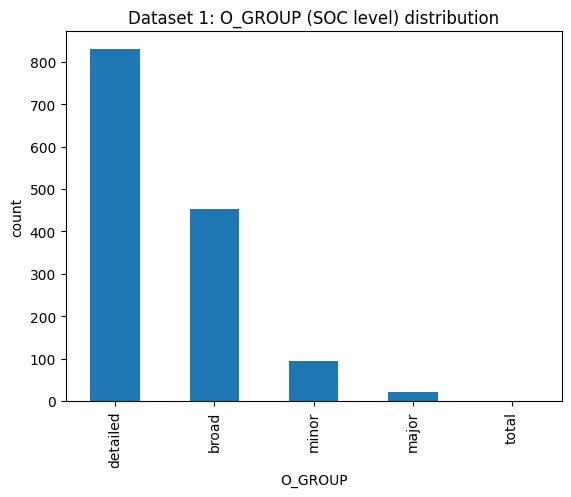

Mode of O_GROUP: detailed


In [4]:
oews_raw['O_GROUP'].value_counts().plot(kind='bar', title='Dataset 1: O_GROUP (SOC level) distribution')
plt.ylabel('count')
plt.show()

print("Mode of O_GROUP:", oews_raw['O_GROUP'].mode()[0])

In [5]:
# Quantitative summary. Wage columns use BLS's '*' suppression code, so we coerce to numeric first.
quant_cols = ['TOT_EMP', 'EMP_PRSE', 'MEAN_PRSE',
              'H_MEAN', 'H_PCT10', 'H_PCT25', 'H_MEDIAN', 'H_PCT75', 'H_PCT90',
              'A_MEAN', 'A_PCT10', 'A_PCT25', 'A_MEDIAN', 'A_PCT75', 'A_PCT90']

oews_numeric = oews_raw[quant_cols].apply(pd.to_numeric, errors='coerce')
oews_numeric.describe().T[['min', '50%', 'mean', 'std', 'max']].rename(columns={'50%': 'median'})

,min,median,mean,std,max
TOT_EMP,220.00,69990.000,554924.932191,4.342791e+06,1.554957e+08
EMP_PRSE,0.00,1.800,2.954318,3.569802e+00,3.500000e+01
MEAN_PRSE,0.00,0.600,1.108280,1.471560e+00,1.590000e+01
H_MEAN,15.37,30.590,37.152273,2.259654e+01,2.413700e+02
H_PCT10,8.70,18.510,21.441348,8.658766e+00,1.035600e+02
H_PCT25,12.41,22.535,26.704242,1.362038e+01,1.617200e+02
H_MEDIAN,14.85,28.335,34.562106,2.259970e+01,2.687600e+02
H_PCT75,17.09,36.525,44.270917,2.964469e+01,2.933000e+02
H_PCT90,18.39,45.430,55.944705,3.847224e+01,3.493500e+02
A_MEAN,31980.00,65450.000,78378.271162,4.683166e+04,5.020500e+05


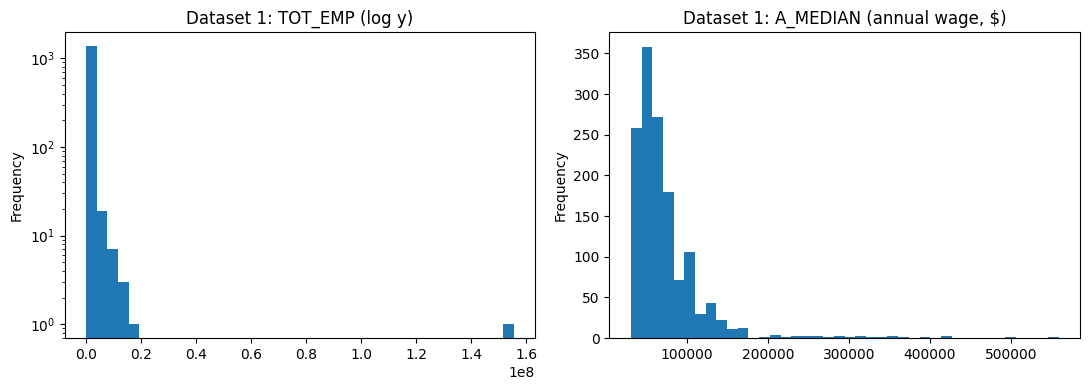

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
oews_numeric['TOT_EMP'].plot(kind='hist', bins=40, logy=True, ax=axes[0], title='Dataset 1: TOT_EMP (log y)')
oews_numeric['A_MEDIAN'].plot(kind='hist', bins=40, ax=axes[1], title='Dataset 1: A_MEDIAN (annual wage, $)')
plt.tight_layout()
plt.show()

**Summary:** `detailed` is the mode of `O_GROUP` (830 of 1,401 rows, ~59%) — BLS reports
one `total` row, a handful of `major`/`minor` groups, and progressively more `broad` and
`detailed` occupations as the classification gets finer. Employment (`TOT_EMP`) is extremely
right-skewed — most occupations are small, with a long tail up to the ~155.5M `All Occupations`
grand-total row (worth remembering that row is a total, not a peer occupation, in later phases).
Wages (units = USD) look reasonable: no negatives, and the national median annual wage sits
around $50k, in line with published BLS topline figures. `JOBS_1000`, `LOC_QUOTIENT`,
`PCT_TOTAL`, `PCT_RPT` are omitted from the table above since they're 100% missing here (handled
in Step 2a).

### Step 1c — Load Dataset 2 (AIOE Appendix A) and get its shape

In [7]:
aioe_raw = pd.read_excel(f'{DATA_DIR}/AIOE_DataAppendix.xlsx', sheet_name='Appendix A')
print('Shape (rows, columns):', aioe_raw.shape)
aioe_raw.head()

Shape (rows, columns): (774, 3)


,SOC Code,Occupation Title,AIOE
0,11-1011,Chief Executives,1.334246
1,11-1021,General and Operations Managers,0.574877
2,11-2011,Advertising and Promotions Managers,1.294387
3,11-2021,Marketing Managers,1.315032
4,11-2022,Sales Managers,1.266280


**Summary:** Dataset 2 has **774 rows and 3 columns** — one AIOE score per SOC occupation.

### Step 1d — Classify & summarize Dataset 2's columns

In [8]:
aioe_raw.dtypes

SOC Code                str
Occupation Title        str
AIOE                float64
dtype: object

| Column | Type | Notes |
|---|---|---|
| `SOC Code` | Categorical (nominal) | 6-digit occupation identifier, unique per row |
| `Occupation Title` | Categorical (nominal) | Occupation name, paired 1:1 with `SOC Code` |
| `AIOE` | Quantitative (continuous) | Standardized (z-scored) exposure index, unitless |

In [9]:
print('Unique SOC codes:', aioe_raw['SOC Code'].nunique(), '/', len(aioe_raw))
print('Unique occupation titles:', aioe_raw['Occupation Title'].nunique(), '/', len(aioe_raw))
aioe_raw['AIOE'].describe()[['min', '50%', 'mean', 'std', 'max']].rename({'50%': 'median'})

Unique SOC codes: 774 / 774
Unique occupation titles: 774 / 774


min      -2.669758e+00
median   -5.119285e-02
mean     -6.847545e-09
std       1.000000e+00
max       1.527667e+00
Name: AIOE, dtype: float64

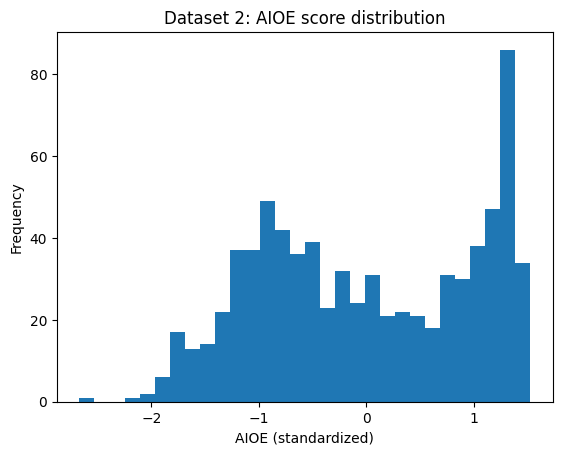

In [10]:
aioe_raw['AIOE'].plot(kind='hist', bins=30, title='Dataset 2: AIOE score distribution')
plt.xlabel('AIOE (standardized)')
plt.show()

**Summary:** both `SOC Code` and `Occupation Title` are unique per row — there's no
categorical "mode" beyond that. `AIOE` has mean ≈ 0 and std ≈ 1, exactly what a standardized
index should show, which is a useful sanity check before we use it as the regression's
independent variable.

## Step 2 — Data Wrangling

We wrangle each dataset, check the two datasets are compatible for the eventual join, then save
out cleaned copies.

### Step 2a — Dataset 1: missing data

In [11]:
oews_raw.isna().sum()[lambda s: s > 0]

JOBS_1000       1401
LOC_QUOTIENT    1401
PCT_TOTAL       1401
PCT_RPT         1401
ANNUAL          1320
HOURLY          1394
dtype: int64

**What's missing and why:**
- `JOBS_1000`, `LOC_QUOTIENT`, `PCT_TOTAL`, `PCT_RPT` — 100% missing. BLS documents these as
  "only available for state/MSA" or "national industry" files; this is the national/cross-industry
  file, so they're structurally not applicable, not unknown. **We drop these columns.**
- `ANNUAL`, `HOURLY` — blank means the flag doesn't apply (`False`), not unknown. **We recode
  blank → `False`.**
- Wage columns show up as missing indirectly, through BLS's `'*'` suppression code rather than a
  blank cell (see Step 1b) — an occupation paid only annually has no hourly wage to report, and
  vice versa. **We convert `'*'` to `NaN` and leave it missing** rather than imputing a mean,
  since "not paid on this basis" is a true fact, not an unmeasured gap.

In [12]:
oews = oews_raw.drop(columns=['JOBS_1000', 'LOC_QUOTIENT', 'PCT_TOTAL', 'PCT_RPT']).copy()

oews['ANNUAL'] = oews['ANNUAL'].fillna(False).astype(bool)
oews['HOURLY'] = oews['HOURLY'].fillna(False).astype(bool)

wage_cols = ['H_MEAN', 'H_PCT10', 'H_PCT25', 'H_MEDIAN', 'H_PCT75', 'H_PCT90',
             'A_MEAN', 'A_PCT10', 'A_PCT25', 'A_MEDIAN', 'A_PCT75', 'A_PCT90']
oews[wage_cols] = oews[wage_cols].apply(pd.to_numeric, errors='coerce')

oews.isna().sum()[lambda s: s > 0]

H_MEAN      81
A_MEAN       7
H_PCT10     81
H_PCT25     81
H_MEDIAN    81
H_PCT75     81
H_PCT90     81
A_PCT10      7
A_PCT25      7
A_MEDIAN     7
A_PCT75      7
A_PCT90      7
dtype: int64

**Summary:** after cleaning, the only remaining missing values are the 81 suppressed
hourly-wage cells (annual-only occupations) and 7 suppressed annual-wage cells (hourly-only
occupations) — exactly the structural pattern we expected, correctly left as `NaN`.

### Step 2b — Dataset 1: range & format checks

In [13]:
print('TOT_EMP negative values:', (oews['TOT_EMP'] < 0).sum())
print('Wage columns negative values:', (oews[wage_cols] < 0).sum().sum())
print('EMP_PRSE/MEAN_PRSE outside [0, 100]:', (~oews[['EMP_PRSE', 'MEAN_PRSE']].apply(lambda s: s.between(0, 100))).sum().sum())
print('OCC_CODE not matching DD-DDDD format:', (~oews['OCC_CODE'].str.match(r'^\d{2}-\d{4}$')).sum())
print('TOT_EMP not rounded to nearest 10:', (oews['TOT_EMP'] % 10 != 0).sum())

TOT_EMP negative values: 0
Wage columns negative values: 0
EMP_PRSE/MEAN_PRSE outside [0, 100]: 0
OCC_CODE not matching DD-DDDD format: 0
TOT_EMP not rounded to nearest 10: 0


**Summary:** every check passes — no negative employment or wages, PRSE values are valid
percentages, every `OCC_CODE` matches the SOC `DD-DDDD` format, and every `TOT_EMP` is rounded
to the nearest 10 as BLS documents. Nothing needed a fix here; this step confirms the data is
already in range and correctly formatted.

### Step 2c — Dataset 1: duplicate check

In [14]:
print('Fully duplicated rows:', oews.duplicated().sum())

dup_occ = oews[oews.duplicated(subset=['OCC_CODE'], keep=False)]
dup_occ[['OCC_CODE', 'OCC_TITLE', 'O_GROUP']].sort_values('OCC_CODE')

Fully duplicated rows: 0


,OCC_CODE,OCC_TITLE,O_GROUP
76,13-1020,Buyers and Purchasing Agents,broad
77,13-1020,Buyers and Purchasing Agents,detailed
109,13-2020,Property Appraisers and Assessors,broad
110,13-2020,Property Appraisers and Assessors,detailed
571,29-2010,Clinical Laboratory Technologists and Technicians,broad
572,29-2010,Clinical Laboratory Technologists and Technicians,detailed
610,31-1120,Home Health and Personal Care Aides,broad
611,31-1120,Home Health and Personal Care Aides,detailed
777,39-7010,Tour and Travel Guides,broad
778,39-7010,Tour and Travel Guides,detailed


**Summary:** no fully duplicated rows. Seven `OCC_CODE` values appear twice, but each pair
is one `broad` row and one `detailed` row for the same occupation — BLS's documented behavior
for occupations aggregated to the broad SOC level. These are two distinct, legitimate estimates,
so **we keep both** rather than removing either.

### Step 2d — Dataset 2: missing data, range, format & duplicate checks

In [15]:
aioe = aioe_raw.copy()

print('Missing values:\n', aioe.isna().sum())
print('\nFully duplicated rows:', aioe.duplicated().sum())
print('Duplicated SOC Code values:', aioe['SOC Code'].duplicated().sum())
print('SOC Code not matching DD-DDDD format:', (~aioe['SOC Code'].str.match(r'^\d{2}-\d{4}$')).sum())
print('AIOE values with |z| > 4 (implausible):', (aioe['AIOE'].abs() > 4).sum())

Missing values:
 SOC Code            0
Occupation Title    0
AIOE                0
dtype: int64

Fully duplicated rows: 0
Duplicated SOC Code values: 0
SOC Code not matching DD-DDDD format: 0
AIOE values with |z| > 4 (implausible): 0


**Summary:** Dataset 2 needs no cleaning — no missing values, no duplicate rows or SOC
codes, every SOC code is correctly formatted, and every `AIOE` value is a plausible standardized
score. We confirm this rather than assume it, since "the file looked clean" isn't the same as
having checked.

### Step 2e — Cross-dataset compatibility check

In [16]:
detailed_oews = oews[oews['O_GROUP'] == 'detailed']
matched = detailed_oews['OCC_CODE'].isin(aioe['SOC Code'])

print(f'Detailed-level Dataset 1 occupations: {len(detailed_oews)}')
print(f'  match a Dataset 2 SOC Code: {matched.sum()} ({matched.mean():.0%})')
print(f'  do NOT match:               {(~matched).sum()}')

detailed_oews.loc[~matched, ['OCC_CODE', 'OCC_TITLE']].head(10)

Detailed-level Dataset 1 occupations: 830
  match a Dataset 2 SOC Code: 673 (81%)
  do NOT match:               157


,OCC_CODE,OCC_TITLE
14,11-2032,Public Relations Managers
15,11-2033,Fundraising Managers
18,11-3012,Administrative Services Managers
19,11-3013,Facilities Managers
52,11-9072,"Entertainment and Recreation Managers, Except ..."
68,11-9171,Funeral Home Managers
69,11-9179,"Personal Service Managers, All Other"
77,13-1020,Buyers and Purchasing Agents
91,13-1082,Project Management Specialists
110,13-2020,Property Appraisers and Assessors


**Summary:** 673 of 830 detailed occupations (81%) join cleanly to Dataset 2 by SOC code.
The rest mostly look like newer/re-split SOC codes (e.g. `13-1082 Project Management
Specialists`) introduced after AIOE's 2021 paper — a genuine SOC-taxonomy version gap, not a
cleaning error. Flagging it now means the merge step in the next phase can plan for a SOC
crosswalk instead of silently losing 19% of occupations.

### Step 2f — Save the cleaned datasets

In [17]:
oews.to_csv('dataset1_new.csv', index=False)
aioe.to_csv('dataset2_new.csv', index=False)

print('Saved dataset1_new.csv:', oews.shape)
print('Saved dataset2_new.csv:', aioe.shape)

Saved dataset1_new.csv: (1401, 28)
Saved dataset2_new.csv: (774, 3)


**Summary:** the cleaned versions of both datasets are saved as `dataset1_new.csv`
(cleaned OEWS, 1,401 rows × 28 columns) and `dataset2_new.csv` (AIOE Appendix A, unchanged
content, 774 rows × 3 columns). Later phases — the SOC crosswalk, the merge, and the regression
— should load these two files directly instead of re-running this notebook's cleaning steps.

## Overall Summary

| | Dataset 1 — BLS OEWS | Dataset 2 — AIOE (Appendix A) |
|---|---|---|
| Raw shape | 1,401 rows × 32 columns | 774 rows × 3 columns |
| Cleaned shape | 1,401 rows × 28 columns | 774 rows × 3 columns (unchanged) |
| Columns dropped | 4 — structurally N/A at national/cross-industry scope | 0 |
| Missing-data handling | `'*'` wage-suppression → `NaN` (left missing, not imputed); `ANNUAL`/`HOURLY` blanks → `False` | none needed |
| Rows removed | 0 | 0 |
| Range/format/duplicate issues found | 0 | 0 |
| Saved as | `dataset1_new.csv` | `dataset2_new.csv` |

Both datasets are now cleaned, documented, and saved. We deliberately did not impute anything
BLS itself marks as suppressed or inapplicable — for a project testing whether AI exposure
predicts *real* wage and employment shifts, inventing values in place of "this wasn't measured"
would undermine the very question we're trying to answer with data instead of speculation.